# Gabarito — Equivalência Plana

Este notebook traz a resolução comentada dos exercícios de [`0419a_equivalencia_plana.ipynb`](0419a_equivalencia_plana.ipynb).

⚠️ **Antes de olhar aqui:** tente resolver os exercícios sozinho no notebook original e use as células de verificação (`assert`) para conferir sua resposta. Volte a este gabarito só depois de tentar — ou se travar de verdade em algum passo.

In [1]:
# Imports e ferramentas necessários para os exercícios abaixo (reconstruídos do notebook principal)
import math
import random
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Arc, Polygon, Rectangle, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas do notebook principal e dos anteriores (0401a, 0402a, 0407a, 0410a e 0417a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def vetorial(u, v) -> float:
    """Produto vetorial de dois vetores do plano, u₁v₂ − u₂v₁: positivo se v está à esquerda de u (módulo 07)."""
    return float(u[0] * v[1] - u[1] * v[0])


def pe_da_altura(X, P, Q) -> np.ndarray:
    """Pé da perpendicular baixada de X sobre a reta PQ (0407a)."""
    X, P, Q = (np.asarray(Z, dtype=float) for Z in (X, P, Q))
    u = Q - P
    return P + np.dot(X - P, u) / np.dot(u, u) * u


def distancia_ponto_reta(X, P, Q) -> float:
    """Distância do ponto X à reta PQ: a medida de X até o pé da perpendicular (0407a)."""
    return math.dist(X, pe_da_altura(X, P, Q))


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=8)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=9)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 6) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2, zorder=7))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none",
                           zorder=7))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2,
                         zorder=7))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def marcar_angulo_reto(ax, vertice, P, Q, tamanho: float = 0.3, cor: str = NORD_TEXTO_SEC) -> None:
    """Quadradinho de ângulo reto no `vertice`, entre as direções de P e de Q."""
    v = np.asarray(vertice, dtype=float)
    u = (np.asarray(P, dtype=float) - v) / math.dist(P, v)
    w = (np.asarray(Q, dtype=float) - v) / math.dist(Q, v)
    canto = [v, v + tamanho * u, v + tamanho * (u + w), v + tamanho * w]
    ax.add_patch(Polygon(canto, closed=True, fill=False, edgecolor=cor, lw=1.5, zorder=7))


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=9)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=9)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


# Ferramentas novas deste notebook
# Cores fixas: figura original azul-claro; peça que se move (o "corte") amarela; figura obtida (a equivalente)
# verde; base roxa; altura laranja; vão ou erro vermelho. As peças de um quebra-cabeça usam CORES_PECAS.
COR_FIGURA = COR_PONTO  # figura original: azul-claro
COR_MOVEL = COR_AVISO  # peça cortada que se desloca: amarelo
COR_RESULTADO = COR_DESTAQUE  # figura equivalente obtida: verde
COR_BASE = COR_EXTRA  # base: roxo
COR_ALTURA = "#D08770"  # altura: laranja
COR_VAO = COR_ALERTA  # vão, sobreposição ou erro: vermelho
CORES_PECAS = ("#88C0D0", "#A3BE8C", "#EBCB8B", "#BF616A", "#B48EAD", "#D08770", "#81A1C1", "#8FBCBB", "#5E81AC")


def area_cadarco(pontos) -> float:
    """Área de um polígono simples (lados que não se cruzam) a partir dos vértices EM ORDEM, pela fórmula do
    cadarço: S = |x₁y₂ − x₂y₁ + x₂y₃ − x₃y₂ + ... + xₙy₁ − x₁yₙ| / 2.

    É uma "régua de área" de CONFERÊNCIA: a justificativa chega em Geometria Analítica (módulo 07), e nenhuma
    demonstração deste notebook depende dela.
    """
    P = np.asarray(pontos, dtype=float)
    x, y = P[:, 0], P[:, 1]
    return abs(float(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))) / 2


def desenhar_peca(ax, pontos, cor: str = COR_FIGURA, opacidade: float = 0.55, borda: str = NORD_TEXTO,
                  largura: float = 1.5, estilo: str = "-", rotulo: str | None = None, tamanho: int = 11,
                  zorder: int = 3) -> None:
    """Desenha uma peça (polígono) pintada, com contorno; `rotulo` é escrito no centro da peça."""
    P = np.asarray(pontos, dtype=float)
    ax.add_patch(Polygon(P, closed=True, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=zorder))
    ax.add_patch(Polygon(P, closed=True, fill=False, edgecolor=borda, lw=largura, linestyle=estilo,
                         zorder=zorder + 1))
    if rotulo:
        ax.text(*P.mean(axis=0), rotulo, color=NORD_TEXTO, fontsize=tamanho, fontweight="bold", ha="center",
                va="center", zorder=zorder + 2)


def desenhar_contorno(ax, pontos, cor: str = NORD_TEXTO_SEC, largura: float = 1.5, estilo: str = "--",
                      zorder: int = 2) -> None:
    """Só o contorno (tracejado) de um polígono: a "sombra" de onde uma peça estava ou vai ficar."""
    ax.add_patch(Polygon(np.asarray(pontos, dtype=float), closed=True, fill=False, edgecolor=cor, lw=largura,
                         linestyle=estilo, zorder=zorder))


def girar(pontos, centro, graus: float) -> np.ndarray:
    """Gira os pontos em torno de `centro` por `graus` (sentido anti-horário). Giro é um movimento rígido:
    a figura girada é congruente à original."""
    c = np.asarray(centro, dtype=float)
    u, v = direcao(graus), direcao(graus + 90)
    return np.array([c + (p[0] - c[0]) * u + (p[1] - c[1]) * v for p in np.asarray(pontos, dtype=float)])


def transladar(pontos, vetor) -> np.ndarray:
    """Desliza todos os pontos pelo mesmo `vetor` (translação, outro movimento rígido)."""
    return np.asarray(pontos, dtype=float) + np.asarray(vetor, dtype=float)


def mover(pontos, t: float, centro=None, graus: float = 0.0, vetor=(0.0, 0.0)) -> np.ndarray:
    """Fração t (de 0 a 1) de um movimento: gira graus·t em torno de `centro` e depois desliza vetor·t.
    Com t = 0 a peça está no lugar de origem; com t = 1, no lugar de destino (é o que anima os widgets)."""
    P = np.asarray(pontos, dtype=float)
    if centro is not None and graus:
        P = girar(P, centro, graus * t)
    return transladar(P, t * np.asarray(vetor, dtype=float))


def movimento_rigido(origem, destino):
    """Dado um triângulo `origem` e um triângulo `destino` CONGRUENTE (vértices na ordem correspondente), devolve
    a função que leva cada ponto do plano para a nova posição (giro, translação e talvez reflexão). Recusa
    triângulos que não são congruentes: um movimento rígido não muda distâncias."""
    p, q = np.asarray(origem, dtype=float), np.asarray(destino, dtype=float)
    M = np.column_stack([q[1] - q[0], q[2] - q[0]]) @ np.linalg.inv(np.column_stack([p[1] - p[0], p[2] - p[0]]))
    if not np.allclose(M.T @ M, np.eye(2), atol=1e-9):
        raise ValueError("os triângulos não são congruentes: não existe movimento rígido entre eles")
    return lambda pontos: (M @ (np.asarray(pontos, dtype=float) - p[0]).T).T + q[0]


# Ferramentas das seções 3 a 5 do notebook principal
def area_triangulo_pontos(A, B, C) -> float:
    """Área do triângulo ABC por base × altura / 2: base AB e altura = distância de C à reta AB (seção 2)."""
    return math.dist(A, B) * distancia_ponto_reta(C, A, B) / 2


def triangulo_sorteado() -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Três vértices sorteados que formam um triângulo de verdade (área não muito pequena)."""
    while True:
        A, B, C = (np.array([random.uniform(-6, 6), random.uniform(-6, 6)]) for _ in range(3))
        if area_cadarco([A, B, C]) > 2:
            return A, B, C


MOLDES = {  # cada molde está sobre o segmento de (0, 0) a (1, 0), do lado de cima
    "quadrado": [(0, 0), (1, 0), (1, 1), (0, 1)],
    "triângulo equilátero": [(0, 0), (1, 0), (0.5, math.sqrt(3) / 2)],
    "semicírculo": [(0.5 - 0.5 * math.cos(t), 0.5 * math.sin(t)) for t in np.linspace(0, math.pi, 2001)],
    "casinha": [(0, 0), (1, 0), (1, 0.6), (0.5, 1.0), (0, 0.6)],
}


def figura_sobre_lado(P, Q, molde, para_fora: bool = True) -> np.ndarray:
    """Copia o `molde` sobre o segmento PQ (o lado (0,0)–(1,0) do molde vai para PQ). Com o triângulo em sentido
    anti-horário, `para_fora=True` desenha a figura do lado de fora (à direita de quem anda de P para Q)."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = Q - P
    normal = np.array([u[1], -u[0]]) * (1 if para_fora else -1)
    return np.array([P + s * u + t * normal for s, t in molde])


def anti_horario(pontos) -> np.ndarray:
    """Devolve os vértices em sentido anti-horário (inverte a ordem se estiverem no horário)."""
    P = np.asarray(pontos, dtype=float)
    x, y = P[:, 0], P[:, 1]
    return P if np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)) > 0 else P[::-1]


def quebra_cabeca(x: int = 3, y: int = 5) -> tuple[list, list]:
    """As quatro peças do quebra-cabeça "64 = 65" (com x = 3 e y = 5): no quadrado de lado x + y e no
    "retângulo" y × (x + 2y). Cada peça do retângulo é obtida da peça do quadrado por um movimento rígido."""
    L = x + y
    no_quadrado = [
        [(0, 0), (L, 0), (0, x)],  # triângulo de catetos L e x
        [(L, x), (0, x), (L, 0)],  # o outro triângulo
        [(0, x), (y, x), (x, L), (0, L)],  # trapézio de bases y e x, altura y
        [(L, L), (x, L), (y, x), (L, x)],  # o outro trapézio
    ]
    C = L + y  # comprimento do retângulo
    destinos = [  # para onde vão três vértices de cada peça (na mesma ordem)
        [(L, 0), (0, 0), (L, x)],
        [(y, y), (C, y), (y, y - x)],
        [(C, 0), (C, y), (L, x)],
        [(0, y), (0, 0), (y, y - x)],
    ]
    no_retangulo = [movimento_rigido(p[:3], d)(p) for p, d in zip(no_quadrado, destinos)]
    return no_quadrado, no_retangulo


SETA = [(0, 1), (5, 1), (5, 0), (8, 2.5), (5, 5), (5, 4), (0, 4)]

## Básico

**Exercício 1.** Áreas por transformação: paralelogramo, triângulo, trapézio e losango.

In [2]:
# (a) Paralelogramo: base × ALTURA = 8·4 = 32 (o lado inclinado 5 não entra na conta)
area_ex1a = 8 * 4

# (b) Triângulo: metade do paralelogramo de mesma base e altura: 14·12/2 = 84
area_ex1b = 14 * 12 / 2

# (c) Trapézio: base média (12 + 7)/2 = 9,5 vezes a altura 6 = 57
area_ex1c = (12 + 7) * 6 / 2

# (d) Losango: metade do retângulo 16 × 30 = 240. As semidiagonais 8 e 15 são catetos de um triângulo retângulo
#     cuja hipotenusa é o lado: √(64 + 225) = 17. Como o losango é um paralelogramo, área = lado × altura.
area_ex1d = 16 * 30 / 2
lado_ex1d = math.hypot(8, 15)
altura_ex1d = area_ex1d / lado_ex1d

print(area_ex1a, area_ex1b, area_ex1c, area_ex1d, lado_ex1d, altura_ex1d)

32 84.0 57.0 240.0 17.0 14.117647058823529


No item (a), o "5" é uma pegadinha: o lado inclinado só entraria na conta se o paralelogramo fosse um retângulo (aí a altura seria o próprio lado). Com altura 4 e lado 5, o "deslocamento" do lado de cima é 3 (triângulo 3–4–5). No item (d), a altura $\frac{240}{17} \approx 14{,}12$ é a distância entre dois lados opostos do losango, e ela é **menor** que o lado 17, como deve ser: a altura é um cateto de um triângulo retângulo cuja hipotenusa é o lado.

**Exercício 2.** O lado do quadrado equivalente.

In [3]:
# (a) Retângulo 18 × 8: área 144, quadrado de lado √144 = 12 (a média geométrica de 18 e 8)
lado_ex2a = math.sqrt(18 * 8)

# (b) Triângulo de base 12 e altura 6: área 36, lado 6
lado_ex2b = math.sqrt(12 * 6 / 2)

# (c) Trapézio de bases 10 e 6 e altura 4: área (16·4)/2 = 32, lado √32 = 4√2
lado_ex2c = math.sqrt((10 + 6) * 4 / 2)

# (d) Losango de diagonais 4 e 8: área 16, lado 4
lado_ex2d = math.sqrt(4 * 8 / 2)

print(lado_ex2a, lado_ex2b, lado_ex2c, lado_ex2d)

12.0 6.0 5.656854249492381 4.0


A receita é sempre a mesma: **área primeiro, raiz depois**. No item (b), repare que o quadrado de lado 6 não é "o triângulo arrumado": ele tem área 36, a mesma do triângulo, e a seção 5 mostra como cortar um no outro de verdade (o triângulo vira o retângulo $12 \times 3$, e o retângulo vira o quadrado $6 \times 6$).

**Exercício 3.** Razões de áreas.

In [4]:
# (a) ABD e ADC têm a mesma altura (a de A até BC): as áreas estão na razão das bases, 1 : 3.
#     Dividindo 60 em 1 + 3 = 4 partes: 15 e 45.
S_ABD_ex3 = 60 * 1 / 4
S_ADC_ex3 = 60 * 3 / 4

# (b) As três medianas dividem o triângulo em 6 pedaços de 60/6 = 10; GBC é formado por dois deles.
S_GBC_ex3 = 2 * 60 / 6

# (c) Pizzas são semelhantes: k = 20/30 = 2/3, e as áreas (e o preço) seguem k² = 4/9
preco_ex3 = 36 * (20 / 30) ** 2

# (d) k = 1,5 ⇒ a área fica multiplicada por 2,25: aumento de 125%
aumento_ex3 = (1.5**2 - 1) * 100

# (e) Escala 1 : 50 ⇒ k = 1/50 e k² = 1/2500. 300 m² / 2500 = 0,12 m² = 0,12 · 10 000 cm² = 1200 cm²
maquete_ex3 = 300 / 50**2 * 10_000

print(S_ABD_ex3, S_ADC_ex3, S_GBC_ex3, preco_ex3, aumento_ex3, maquete_ex3)

15.0 45.0 20.0 16.0 125.0 1200.0


O item (d) é um clássico de prova: a resposta **não** é 50% (isso seria o aumento de cada lado) nem 100%. Como $1{,}5^2 = 2{,}25$, a área nova é 225% da antiga, ou seja, **125% a mais**. No item (e), cuidado com a conversão de unidades: $1 \text{ m}^2 = (100 \text{ cm})^2 = 10\,000 \text{ cm}^2$, e não $100 \text{ cm}^2$. A própria conversão de unidades de área é um caso da razão $k^2$, com $k = 100$.

## Intermediário

**Exercício 4.** As suas próprias funções.

12.0 6.0
[[[0.0, 0.0], [8.0, 0.0], [5.5, 3.0], [1.5, 3.0]], [[1.5, 3.0], [0.0, 3.0], [-0.0, 0.0]], [[8.0, 3.0], [5.5, 3.0], [8.0, -0.0]]]


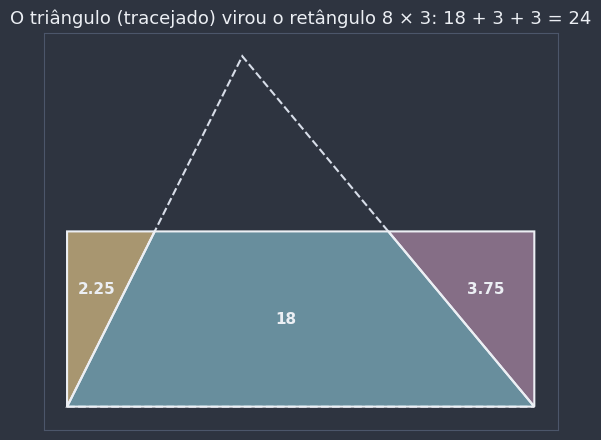

In [5]:
def area_cadarco_ex4(pontos) -> float:
    # Soma de xᵢ·yᵢ₊₁ − xᵢ₊₁·yᵢ, com o último vértice ligado ao primeiro (o % n "dá a volta")
    n = len(pontos)
    soma = sum(pontos[i][0] * pontos[(i + 1) % n][1] - pontos[(i + 1) % n][0] * pontos[i][1] for i in range(n))
    return abs(soma) / 2  # no sentido horário a soma sai negativa: o módulo resolve


def area_paralelogramo_ex4(b: float, h: float) -> float:
    return b * h  # corta um triângulo e desliza: vira o retângulo b × h


def area_triangulo_ex4(b: float, h: float) -> float:
    return b * h / 2  # duas cópias formam um paralelogramo


def area_trapezio_ex4(B: float, b: float, h: float) -> float:
    return (B + b) * h / 2  # duas cópias formam um paralelogramo de base B + b


def area_losango_ex4(d1: float, d2: float) -> float:
    return d1 * d2 / 2  # metade do retângulo d1 × d2


def quadrado_equivalente_ex4(b: float, h: float) -> float:
    return math.sqrt(b * h)  # a média geométrica


def triangulo_para_retangulo_ex4(A, B, C) -> list[np.ndarray]:
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    H = pe_da_altura(C, A, B)  # pé da altura de C (está entre A e B)
    Ma, Mb = ponto_medio(A, C), ponto_medio(B, C)  # extremos da base média
    Hm = ponto_medio(C, H)  # onde a altura corta a base média
    trapezio = np.array([A, B, Mb, Ma])  # fica parado
    esquerda = girar([Ma, Hm, C], Ma, 180)  # meia-volta em torno de Ma: C cai em A
    direita = girar([Hm, Mb, C], Mb, 180)  # meia-volta em torno de Mb: C cai em B
    return [trapezio, esquerda, direita]


pecas_ex4 = triangulo_para_retangulo_ex4((0, 0), (8, 0), (3, 6))
print(area_cadarco_ex4([(0, 0), (4, 0), (4, 3), (0, 3)]), quadrado_equivalente_ex4(12, 3))
print([np.round(p, 3).tolist() for p in pecas_ex4])

fig, ax = plt.subplots(figsize=(9, 4.5))
fig.patch.set_facecolor(NORD_FUNDO)
desenhar_contorno(ax, [(0, 0), (8, 0), (3, 6)], cor=NORD_TEXTO_SEC)
for cor, p in zip((COR_FIGURA, COR_MOVEL, COR_EXTRA), pecas_ex4):
    desenhar_peca(ax, p, cor=cor, opacidade=0.65, rotulo=f"{area_cadarco(p):g}")
preparar_eixo(ax, [(0, 0), (8, 6)], margem=0.4)
ax.set_title("O triângulo (tracejado) virou o retângulo 8 × 3: 18 + 3 + 3 = 24", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

O giro de 180° em torno do ponto médio $M_a$ de $\overline{AC}$ troca $A$ e $C$ de lugar: por isso o vértice $C$ do triangulinho da esquerda cai exatamente em $A$, e o lado $\overline{M_aC}$ cai sobre $\overline{M_aA}$, que já é lado do trapézio. O ponto $H_m$ cai na reta vertical que passa por $A$, à altura $\frac{h}{2}$, fechando o canto do retângulo. Isso só funciona porque o pé $H$ da altura está **entre** $A$ e $B$: com $C$ "fora" da base, um dos triangulinhos sairia do retângulo (é por isso que a seção 5 manda escolher como base o **maior** lado).

**Exercício 5.** Verificações numéricas.

In [6]:
random.seed(5)

# (a) Medianas: os seis pedaços valem S/6
medianas_ok_ex5 = True
for _ in range(100):
    A, B, C = triangulo_sorteado()
    S = area_triangulo_pontos(A, B, C)
    G = (A + B + C) / 3
    Ma, Mb, Mc = ponto_medio(B, C), ponto_medio(C, A), ponto_medio(A, B)
    seis = [(A, Mc, G), (Mc, B, G), (B, Ma, G), (Ma, C, G), (C, Mb, G), (Mb, A, G)]
    medianas_ok_ex5 = medianas_ok_ex5 and all(iguais(area_triangulo_pontos(*t), S / 6) for t in seis)

# (b) Viviani no equilátero de lado 10 (altura 5√3)
A, B, C = np.array([0.0, 0.0]), np.array([10.0, 0.0]), np.array([5.0, 5 * math.sqrt(3)])
viviani_ok_ex5 = True
for _ in range(200):
    r1, r2 = random.random(), random.random()
    if r1 + r2 > 1:  # "dobra" o sorteio para dentro do triângulo
        r1, r2 = 1 - r1, 1 - r2
    P = A + r1 * (B - A) + r2 * (C - A)
    soma = sum(distancia_ponto_reta(P, X, Y) for X, Y in ((A, B), (B, C), (C, A)))
    viviani_ok_ex5 = viviani_ok_ex5 and iguais(soma, 5 * math.sqrt(3))

# (c) Pitágoras generalizado com três moldes
pitagoras_ok_ex5 = True
for b, c in ((3, 4), (5, 12), (1, 2), (2.5, 6)):
    A, B, C = np.array([0.0, 0.0]), np.array([c, 0.0]), np.array([0.0, b])
    for nome in ("quadrado", "triângulo equilátero", "semicírculo"):
        Fc, Fa, Fb = (area_cadarco(figura_sobre_lado(P, Q, MOLDES[nome])) for P, Q in ((A, B), (B, C), (C, A)))
        pitagoras_ok_ex5 = pitagoras_ok_ex5 and iguais(Fa, Fb + Fc)

# (d) Ponto qualquer no paralelogramo de base 9 e altura 5 (área 45)
A, B, C, D = (np.array(p, dtype=float) for p in [(0, 0), (9, 0), (12, 5), (3, 5)])
paralelogramo_ok_ex5 = True
for _ in range(200):
    P = A + random.random() * (B - A) + random.random() * (D - A)
    paralelogramo_ok_ex5 = paralelogramo_ok_ex5 and iguais(area_triangulo_pontos(P, A, B) + area_triangulo_pontos(P, C, D), 45 / 2)

print(medianas_ok_ex5, viviani_ok_ex5, pitagoras_ok_ex5, paralelogramo_ok_ex5)

True True True True


Quatro `True`, como as demonstrações garantem. Mas lembre o que essas células **são**: centenas de exemplos que **ilustram** os teoremas. Quem garante que eles valem para **todos** os triângulos, pontos e moldes são as demonstrações das seções 3 e 4. Uma conferência numérica serve para pegar erros (de conta, de código ou de enunciado) e para ganhar confiança, não para substituir a prova.

**Exercício 6.** Problemas de dois ou três passos.

In [7]:
# (a) Trapézio isósceles de bases 14 e 6: cada "aba" lateral tem base (14 − 6)/2 = 4 e hipotenusa 5,
#     então a altura é o outro cateto: √(25 − 16) = 3. Área = (14 + 6)·3/2 = 30.
altura_ex6a = math.sqrt(5**2 - ((14 - 6) / 2) ** 2)
area_ex6a = (14 + 6) * altura_ex6a / 2

# (b) A área 84 também é (lado 13)·(distância ao lado 13)/2: d = 2·84/13
distancia_ex6b = 2 * 84 / 13

# (c) Canto ADF: com base AD sobre AB, S(ADF)/S(ABF) = AD/AB = 1/3 (mesma altura, a de F).
#     Com base AF sobre AC, S(ABF)/S(ABC) = AF/AC = 2/3 (mesma altura, a de B), porque CF = CA/3.
#     Logo S(ADF) = (1/3)·(2/3)·S = 2/9·S. Os três cantos são iguais (mesmo argumento) e DEF é o que sobra.
canto_ex6c = (1 / 3) * (2 / 3)
razao_ex6c = 1 - 3 * canto_ex6c

print(altura_ex6a, area_ex6a, distancia_ex6b, canto_ex6c, razao_ex6c)

# Conferência em coordenadas, num triângulo sorteado
A, B, C = triangulo_sorteado()
D, E, F = A + (B - A) / 3, B + (C - B) / 3, C + (A - C) / 3
S = area_triangulo_pontos(A, B, C)
print(f"S(ADF)/S = {area_triangulo_pontos(A, D, F) / S:.6f} (2/9 = {2 / 9:.6f});  "
      f"S(DEF)/S = {area_triangulo_pontos(D, E, F) / S:.6f}")

3.0 30.0 12.923076923076923 0.2222222222222222 0.33333333333333337
S(ADF)/S = 0.222222 (2/9 = 0.222222);  S(DEF)/S = 0.333333


O item (c) mostra o "truque da olimpíada" (seção 3) usado **duas vezes seguidas**: para comparar dois triângulos que não têm nem a mesma base nem a mesma altura, passe por um triângulo intermediário ($ABF$) que tenha uma coisa em comum com cada um. O resultado $\frac{1}{3}$ não depende do formato do triângulo, e a conferência num triângulo sorteado confirma.

## Desafio

**Exercício 7.** Qualquer polígono → quadrado.

SETA: (22.5, 4.743416490252569);  polígono sorteado: 9 triângulos, área 50.6049 (régua: 50.6049), lado 7.1137


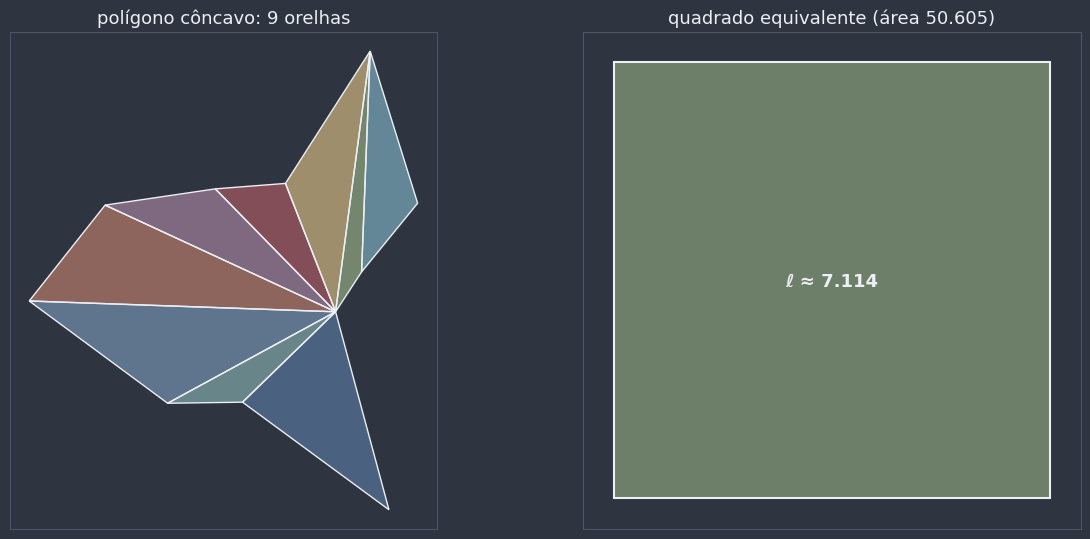

In [8]:
def poligono_para_quadrado_ex7(pontos) -> tuple[list[np.ndarray], float, float]:
    P = [np.asarray(X, dtype=float) for X in anti_horario(pontos)]  # tudo no sentido anti-horário

    def orelha(i: int) -> bool:
        n = len(P)
        A, B, C = P[i - 1], P[i], P[(i + 1) % n]
        if vetorial(B - A, C - B) <= 1e-12:  # vértice "reflexo" (virada à direita): não é orelha
            return False
        outros = [P[j] for j in range(n) if j not in ((i - 1) % n, i, (i + 1) % n)]
        # nenhum outro vértice pode estar dentro (ou na borda) do triângulo ABC
        return not any(all(vetorial(Q - R, X - R) >= -1e-12 for R, Q in ((A, B), (B, C), (C, A))) for X in outros)

    triangulos = []
    while len(P) > 3:
        i = next(i for i in range(len(P)) if orelha(i))  # todo polígono simples tem pelo menos duas orelhas
        triangulos.append(np.array([P[i - 1], P[i], P[(i + 1) % len(P)]]))
        del P[i]  # cortar a orelha deixa um polígono com um vértice a menos
    triangulos.append(np.array(P))

    area, lado = 0.0, 0.0
    for T in triangulos:
        S_T = math.dist(T[0], T[1]) * distancia_ponto_reta(T[2], T[0], T[1]) / 2  # base × altura / 2
        area += S_T
        lado = math.hypot(lado, math.sqrt(S_T))  # o quadrado do triângulo somado ao acumulado (Pitágoras)
    return triangulos, area, lado


random.seed(7)
angulos = [360 * k / 11 + random.uniform(-10, 10) for k in range(11)]
estrela = [random.uniform(1.5, 7) * direcao(a) for a in angulos]
tris, area_e, lado_e = poligono_para_quadrado_ex7(estrela)
print(f"SETA: {poligono_para_quadrado_ex7(SETA)[1:]};  polígono sorteado: {len(tris)} triângulos, área {area_e:.4f} "
      f"(régua: {area_cadarco(estrela):.4f}), lado {lado_e:.4f}")

fig, (ax, ax_q) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
fig.patch.set_facecolor(NORD_FUNDO)
for k, T in enumerate(tris):
    desenhar_peca(ax, T, cor=CORES_PECAS[k % len(CORES_PECAS)], opacidade=0.6, largura=1)
preparar_eixo(ax, estrela, margem=0.5)
ax.set_title(f"polígono côncavo: {len(tris)} orelhas", color=NORD_TEXTO, fontsize=13)
desenhar_peca(ax_q, [(0, 0), (lado_e, 0), (lado_e, lado_e), (0, lado_e)], cor=COR_RESULTADO,
              rotulo=f"ℓ ≈ {lado_e:.3f}", tamanho=13)
preparar_eixo(ax_q, [(0, 0), (lado_e, lado_e)], margem=0.5)
ax_q.set_title(f"quadrado equivalente (área {area_e:.3f})", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

Três detalhes fazem a função funcionar em **qualquer** polígono simples:

1. **Sentido anti-horário.** O teste de "vértice convexo" usa o sinal do produto vetorial ("virar à esquerda"), que só faz sentido se o contorno for percorrido sempre no mesmo sentido. Por isso a primeira linha usa `anti_horario`.
2. **Nenhum vértice dentro da orelha.** Num polígono côncavo, um vértice convexo pode ter outro vértice "escondido" dentro do seu triângulo; cortar ali faria o triângulo sair do polígono. O teste `all(... >= -1e-12)` verifica se o ponto está à esquerda (ou em cima) dos três lados.
3. **Sempre existe uma orelha.** É o **teorema das duas orelhas**: todo polígono simples com mais de três vértices tem pelo menos duas orelhas. Por isso o `next(...)` nunca falha, e cada corte reduz um vértice: no fim, $n - 2$ triângulos, como em 0411a.

A soma dos quadrados é o passo 4 da receita: `math.hypot(lado, novo)` é exatamente $\sqrt{\text{lado}^2 + \text{novo}^2}$.

**Exercício 8.** As lúnulas de Hipócrates, numericamente.

In [9]:
def lunulas_ex8(b: float, c: float) -> tuple[float, float]:
    A, B, C = np.array([0.0, 0.0]), np.array([c, 0.0]), np.array([0.0, b])
    semi = MOLDES["semicírculo"]  # polígono de 2000 lados: um molde exato, sem π
    F_c = area_cadarco(figura_sobre_lado(A, B, semi))  # cateto c, para fora
    F_b = area_cadarco(figura_sobre_lado(C, A, semi))  # cateto b, para fora
    F_a = area_cadarco(figura_sobre_lado(B, C, semi, para_fora=False))  # hipotenusa, para dentro
    S = b * c / 2
    # O semicírculo grande contém o triângulo; o que ele tem A MAIS que o triângulo (F_a − S) é a parte dos
    # semicírculos pequenos que NÃO é lúnula. Tirando isso de F_b + F_c, sobram as lúnulas.
    return F_b + F_c - (F_a - S), S


lunulas_ok_ex8 = all(iguais(*lunulas_ex8(b, c)) for b, c in ((3, 4), (1, 1), (5, 12), (2, 7), (0.5, 3)))
razao_ex8 = area_cadarco(figura_sobre_lado((4, 0), (0, 3), MOLDES["semicírculo"])) / 5**2

print(lunulas_ex8(3, 4), lunulas_ok_ex8, razao_ex8, math.pi / 8)

(6.000000000002046, 6.0) True 0.39269892020776753 0.39269908169872414


A conta não usou $\pi$ em lugar nenhum: os semicírculos são cópias ampliadas de um mesmo molde, e a razão $k^2$ faz todo o trabalho. Mas o item (c) mostra que o número $\pi$ está **escondido** no molde: a área do semicírculo de diâmetro 1 dá $0{,}392699\ldots = \frac{\pi}{8}$. Esse é o caminho de 📌 Áreas de Superfícies Planas: descobrir a área do molde (o círculo de raio 1 tem área $\pi$) e, com $k^2$, a área de qualquer círculo, $\pi r^2$.

**Exercício 9.** Fibonacci e as peças que não encaixam.

{5: -1, 8: 1, 13: -1}
{5: (0.4, 0.3333333333333333), 8: (0.375, 0.4), 13: (0.38461538461538464, 0.375)}
{5: 1.0, 8: 1.0, 13: 1.0}
{5: 'sobreposição', 8: 'vão', 13: 'sobreposição'}


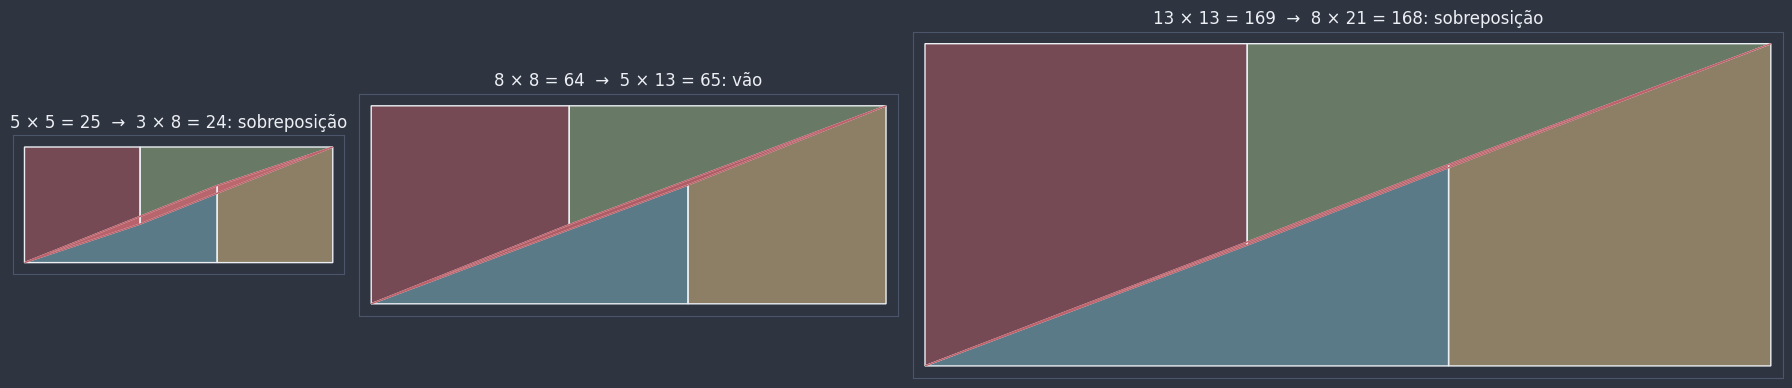

In [10]:
pares = ((2, 3), (3, 5), (5, 8))
diferenca_ex9, inclinacoes_ex9, vao_ex9, tipo_ex9 = {}, {}, {}, {}
for x, y in pares:
    L = x + y  # lado do quadrado
    diferenca_ex9[L] = y * (x + 2 * y) - L**2
    inclinacoes_ex9[L] = (x / L, (y - x) / y)
    vao_ex9[L] = area_cadarco([(0, 0), (L, x), (L + y, y), (y, y - x)])
    tipo_ex9[L] = "vão" if diferenca_ex9[L] > 0 else "sobreposição"

print(diferenca_ex9, inclinacoes_ex9, vao_ex9, tipo_ex9, sep="\n")

fig, eixos = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [8, 13, 21]})
fig.patch.set_facecolor(NORD_FUNDO)
for ax, (x, y) in zip(eixos, pares):
    _, no_retangulo = quebra_cabeca(x, y)
    for cor, pts in zip(CORES_PECAS, no_retangulo):
        desenhar_peca(ax, pts, cor=cor, opacidade=0.5, largura=1)
    L = x + y
    desenhar_peca(ax, [(0, 0), (L, x), (L + y, y), (y, y - x)], cor=COR_VAO, opacidade=0.9, borda=COR_VAO, largura=1)
    preparar_eixo(ax, [(0, 0), (L + y, y)], margem=0.3)
    ax.set_title(f"{L} × {L} = {L * L}  →  {y} × {L + y} = {y * (L + y)}: {tipo_ex9[L]}", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

O padrão alterna: $25 \to 24$ (sobra **sobreposição**: as peças se encavalam ao longo da diagonal), $64 \to 65$ (sobra um **vão**), $169 \to 168$ (sobreposição de novo), sempre com diferença de **exatamente 1**. É a **identidade de Cassini** para a sequência de Fibonacci $F_1 = F_2 = 1$, $F_{k+1} = F_k + F_{k-1}$:

$$F_{k-1} \cdot F_{k+1} - F_k^2 = (-1)^k.$$

Com $F_k$ = lado do quadrado (5, 8, 13), $F_{k-1} = y$ e $F_{k+1} = x + 2y$, o "retângulo" $y \times (x + 2y)$ tem área $F_{k-1} F_{k+1}$, que difere de $F_k^2$ por $\pm 1$. E, quanto mais longe na sequência, mais fina fica a "diagonal" errada (o vão de área 1 se espalha por uma diagonal cada vez mais comprida), o que torna a ilusão ainda mais convincente: com o quadrado $13 \times 13$, o erro é praticamente invisível.